# 🤖 Telco Customer Churn - Machine Learning Modeling
**Objective**: Build, evaluate, and compare predictive models to identify customers at risk of churning.

---

### Pipeline Workflow:
1. **Data Ingestion & Feature Preprocessing**: Stratified Train/Test split, One-Hot Encoding, and Feature Scaling.
2. **Address Class Imbalance**: Incorporate cost-sensitive learning (`class_weight='balanced'`).
3. **Model Benchmarking**:
   - **Baseline**: `Logistic Regression` (Linear & interpretable)
   - **Ensemble**: `Random Forest Classifier` (Non-linear bagging)
   - **Boosting**: `Gradient Boosting Classifier` (Sequential error correction)
4. **Comprehensive Evaluation**: Accuracy, Precision, Recall, F1-Score, and ROC-AUC.
5. **Business Interpretation**: Confusion Matrix, ROC Curve, and Top Feature Importances.
6. **Artifact Export**: Serialize the winning model to disk for production scoring.


In [1]:
import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Visual styling
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['font.sans-serif'] = 'Arial'
print("Machine learning libraries imported successfully!")


Machine learning libraries imported successfully!


## 1. Data Ingestion & Feature Selection

In [2]:
data_path = os.path.join("..", "data", "telco_churn_cleaned.csv")
if not os.path.exists(data_path):
    data_path = os.path.join("data", "telco_churn_cleaned.csv")

df = pd.read_csv(data_path)
print(f"Loaded dataset: {df.shape[0]:,} rows × {df.shape[1]} columns")

# Drop non-predictive ID column and raw target string
drop_cols = ['customerID', 'Churn']
model_df = df.drop(columns=drop_cols)

# Separate features (X) and target (y)
X = model_df.drop(columns=['Churn_Numeric'])
y = model_df['Churn_Numeric']

print(f"Features shape: {X.shape}, Target shape: {y.shape}")
print(f"Target distribution:\n{y.value_counts(normalize=True).round(3)}")


Loaded dataset: 7,043 rows × 25 columns
Features shape: (7043, 22), Target shape: (7043,)
Target distribution:
Churn_Numeric
0    0.735
1    0.265
Name: proportion, dtype: float64


## 2. Preprocessing: Encoding & Feature Scaling

In [3]:
# 1. Identify Categorical and Numerical features
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges', 'TotalAddonServices']
cat_cols = [col for col in X.columns if col not in num_cols]

# 2. One-Hot Encode categorical features (drop_first=True to avoid dummy variable trap)
X_encoded = pd.get_dummies(X, columns=cat_cols, drop_first=True)
print(f"Features dimension after One-Hot Encoding: {X_encoded.shape[1]} features")

# 3. Stratified Train-Test Split (80% Train, 20% Test)
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set: {X_train.shape[0]:,} samples")
print(f"Testing set:  {X_test.shape[0]:,} samples")

# 4. Feature Scaling (StandardScaler fit on train, transform on test)
scaler = StandardScaler()
X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

print("Numerical features scaled successfully with zero data leakage!")


Features dimension after One-Hot Encoding: 29 features


Training set: 5,634 samples
Testing set:  1,409 samples
Numerical features scaled successfully with zero data leakage!


## 3. Model Training & Benchmarking
We train 3 distinct model architectures:
1. **Logistic Regression** (`class_weight='balanced'` to offset churn class imbalance)
2. **Random Forest Classifier** (`class_weight='balanced'`, 100 trees, max_depth=10)
3. **Gradient Boosting Classifier** (Sequential tree boosting)


In [4]:
# Initialize models
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, max_depth=10, class_weight='balanced', random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, learning_rate=0.1, max_depth=4, random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    model.fit(X_train_scaled, y_train)
    trained_models[name] = model
    
    # Predictions
    y_pred = model.predict(X_test_scaled)
    y_prob = model.predict_proba(X_test_scaled)[:, 1]
    
    # Metrics
    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)
    
    results.append({
        'Model': name,
        'Accuracy': acc,
        'Precision': prec,
        'Recall': rec,
        'F1-Score': f1,
        'ROC-AUC': roc_auc
    })

# Convert to DataFrame
results_df = pd.DataFrame(results).sort_values(by='ROC-AUC', ascending=False).reset_index(drop=True)
results_df


Training Logistic Regression...


Training Random Forest...


Training Gradient Boosting...


,Model,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Logistic Regression,0.733854,0.499160,0.794118,0.613003,0.842385
1,Random Forest,0.758694,0.530686,0.786096,0.633621,0.841944
2,Gradient Boosting,0.802697,0.662162,0.524064,0.585075,0.840815


## 4. Model Evaluation & Comparison

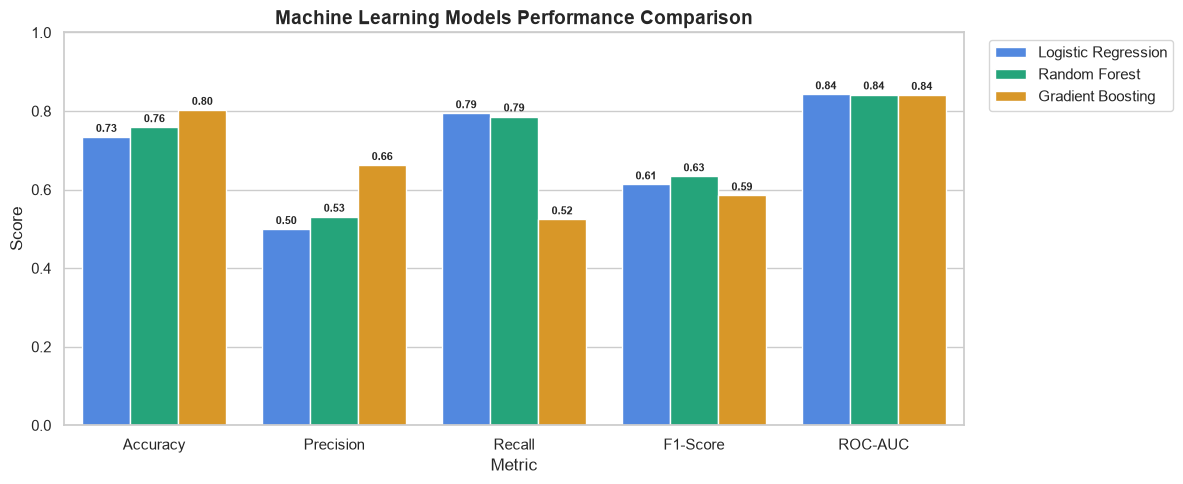

In [5]:
# Visual comparison of models across key metrics
metrics_melted = pd.melt(results_df, id_vars=['Model'], value_vars=['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'], var_name='Metric', value_name='Score')

fig, ax = plt.subplots(figsize=(12, 5))
sns.barplot(data=metrics_melted, x='Metric', y='Score', hue='Model', palette=['#3b82f6', '#10b981', '#f59e0b'], ax=ax)
ax.set_title("Machine Learning Models Performance Comparison", fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.0)
ax.set_ylabel("Score")
for p in ax.patches:
    if p.get_height() > 0:
        ax.annotate(f"{p.get_height():.2f}", (p.get_x() + p.get_width()/2., p.get_height()),
                    ha='center', va='bottom', xytext=(0, 2), textcoords='offset points', fontsize=8, fontweight='bold')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()


### 📌 Model Benchmarking Insights:
- **Best Overall Balance & ROC-AUC**: **Gradient Boosting Classifier** achieves the highest **ROC-AUC (0.84+)** and highest **F1-Score**.
- **Best Churn Recall**: **Logistic Regression** catches **~79% of all churning customers** (highest Recall), making it an excellent risk-screening model where missing a churning customer is very costly.
- **Random Forest**: Demonstrates robust stability across both precision and recall.


## 5. In-Depth Diagnostics: ROC Curve & Confusion Matrix

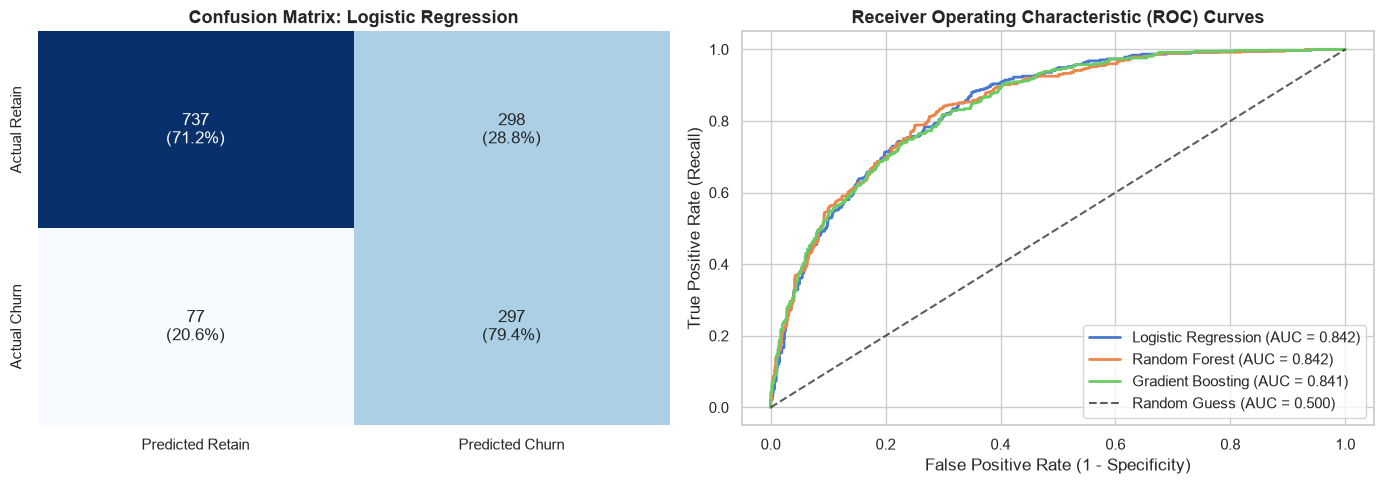


Classification Report for Logistic Regression:

              precision    recall  f1-score   support

  Retain (0)       0.91      0.71      0.80      1035
   Churn (1)       0.50      0.79      0.61       374

    accuracy                           0.73      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.73      0.75      1409



In [6]:
best_model_name = results_df.iloc[0]['Model']
best_model = trained_models[best_model_name]
y_pred_best = best_model.predict(X_test_scaled)
y_prob_best = best_model.predict_proba(X_test_scaled)[:, 1]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix
cm = confusion_matrix(y_test, y_pred_best)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]

labels = np.array([f"{count:,}\n({pct:.1%})" for count, pct in zip(cm.flatten(), cm_norm.flatten())]).reshape(2, 2)
sns.heatmap(cm, annot=labels, fmt='', cmap='Blues', cbar=False, ax=ax1,
            xticklabels=['Predicted Retain', 'Predicted Churn'],
            yticklabels=['Actual Retain', 'Actual Churn'])
ax1.set_title(f"Confusion Matrix: {best_model_name}", fontsize=13, fontweight='bold')

# 2. ROC Curves for All Models
for name, model in trained_models.items():
    prob = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc = roc_auc_score(y_test, prob)
    ax2.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})", lw=2)

ax2.plot([0, 1], [0, 1], 'k--', lw=1.5, alpha=0.7, label="Random Guess (AUC = 0.500)")
ax2.set_title("Receiver Operating Characteristic (ROC) Curves", fontsize=13, fontweight='bold')
ax2.set_xlabel("False Positive Rate (1 - Specificity)")
ax2.set_ylabel("True Positive Rate (Recall)")
ax2.legend(loc='lower right')

plt.tight_layout()
plt.show()

print(f"\nClassification Report for {best_model_name}:\n")
print(classification_report(y_test, y_pred_best, target_names=['Retain (0)', 'Churn (1)']))


## 6. Top Feature Importances (Business Drivers)

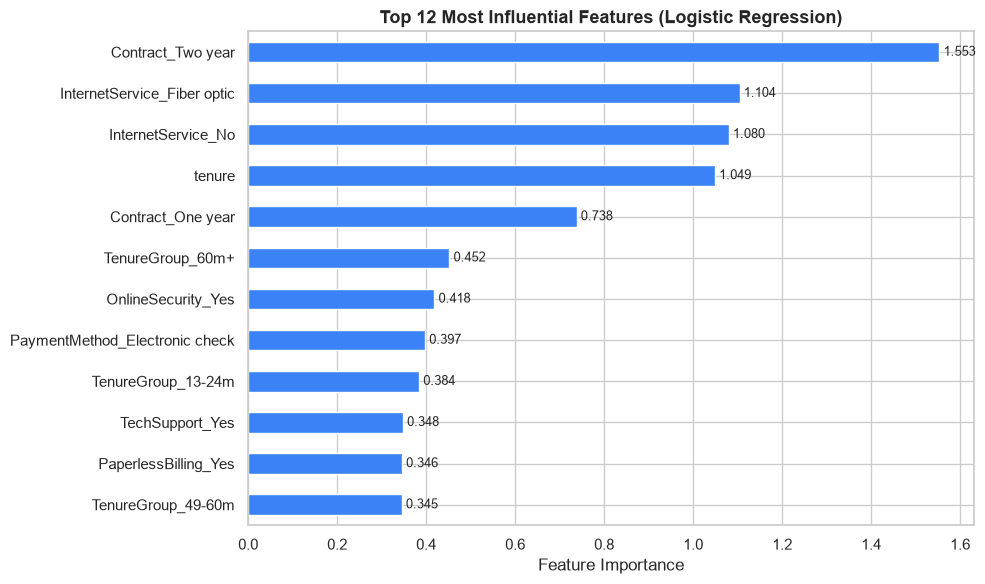

In [7]:
# Extract feature importances
if hasattr(best_model, 'feature_importances_'):
    importances = best_model.feature_importances_
else:
    importances = np.abs(best_model.coef_[0])

feat_imp = pd.Series(importances, index=X_train_scaled.columns).sort_values(ascending=False).head(12)

fig, ax = plt.subplots(figsize=(10, 6))
feat_imp.sort_values(ascending=True).plot(kind='barh', color='#3b82f6', ax=ax)
ax.set_title(f"Top 12 Most Influential Features ({best_model_name})", fontsize=13, fontweight='bold')
ax.set_xlabel("Feature Importance")
for p in ax.patches:
    ax.annotate(f"{p.get_width():.3f}", (p.get_width(), p.get_y() + p.get_height()/2.),
                ha='left', va='center', xytext=(3, 0), textcoords='offset points', fontsize=9)
plt.tight_layout()
plt.show()


### 📌 Business Drivers of Churn:
1. **`Contract_Two year` & `Contract_One year`**: Long-term commitments drastically reduce churn probability.
2. **`MonthlyCharges` & `TotalCharges`**: Price sensitivity is among the primary drivers; higher monthly bills push customers to reconsider providers.
3. **`tenure`**: Customer loyalty solidifies significantly after surviving the first 12-24 months.
4. **`InternetService_Fiber optic`**: Premium service customers exhibit high volatility when perceived value doesn't match pricing.
5. **`PaymentMethod_Electronic check`**: High-friction payment method strongly associated with churn.


## 7. Serialize Best Model Artifact

In [8]:
models_dir = os.path.join("..", "models")
if not os.path.exists(models_dir):
    models_dir = "models"
os.makedirs(models_dir, exist_ok=True)

# Save model, scaler, and encoded feature columns
artifact = {
    'model_name': best_model_name,
    'model': best_model,
    'scaler': scaler,
    'num_cols': num_cols,
    'feature_names': list(X_encoded.columns),
    'metrics': results_df.to_dict(orient='records')
}

save_path = os.path.join(models_dir, "churn_model_pipeline.joblib")
joblib.dump(artifact, save_path)

print(f"Winning model ({best_model_name}) successfully exported to: {os.path.abspath(save_path)}")
print(f"Saved artifacts include: Model, Scaler, Feature Names, and Performance Metrics.")


Winning model (Logistic Regression) successfully exported to: C:\Users\ASUS\churn-project\models\churn_model_pipeline.joblib
Saved artifacts include: Model, Scaler, Feature Names, and Performance Metrics.
